In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

Number of Rows: 20640
Number of Columns: 9

Column Names:
Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


In [4]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [6]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [7]:
df = df.drop_duplicates()

df = df.dropna()

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("Total Records After Cleaning:", len(df))

Missing Values After Cleaning:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64
Total Records After Cleaning: 20640


In [8]:
X = df[['MedInc']]

y = df['MedHouseVal']

print("Input Feature (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

Input Feature (X):
   MedInc
0  8.3252
1  8.3014
2  7.2574
3  5.6431
4  3.8462

Target Variable (y):
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64


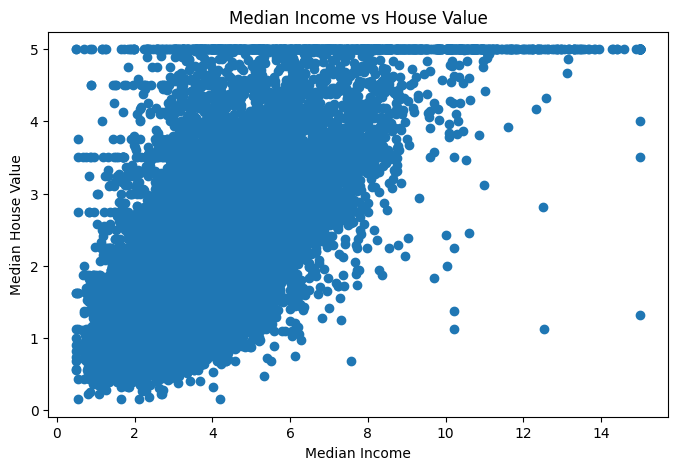

In [9]:
plt.figure(figsize=(8,5))

plt.scatter(X['MedInc'], y)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 16512
Testing Records: 4128


In [11]:
model = LinearRegression()

print("Linear Regression Model Created")

Linear Regression Model Created


In [12]:
model.fit(X_train, y_train)

print("Model Training Completed Successfully")

Model Training Completed Successfully


In [13]:
print("Coefficient:", model.coef_[0])

print("Intercept:", model.intercept_)

Coefficient: 0.4193384939381271
Intercept: 0.4445972916907879


In [14]:
y_pred = model.predict(X_test)

print("Predictions Generated Successfully")

Predictions Generated Successfully


In [15]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

comparison.head(10)

,Actual Price,Predicted Price
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [16]:
mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.629908653009376


In [17]:
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.7091157771765549


In [18]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 0.8420901241414455


In [19]:
r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: 0.45885918903846656


In [20]:
print("MODEL EVALUATION RESULTS")

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MODEL EVALUATION RESULTS
MAE: 0.629908653009376
MSE: 0.7091157771765549
RMSE: 0.8420901241414455
R2 Score: 0.45885918903846656


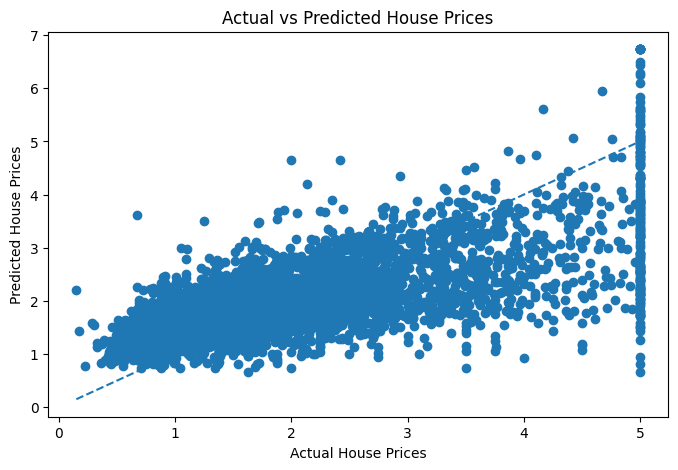

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.show()

In [22]:
new_house = pd.DataFrame({
    'MedInc': [5.0]
})

predicted_price = model.predict(new_house)

print("Predicted House Value:", predicted_price[0])

print("Predicted Price in Dollars:",
      predicted_price[0] * 100000)

Predicted House Value: 2.5412897613814236
Predicted Price in Dollars: 254128.97613814235


## Conclusion

In this activity, I developed a Simple Linear Regression model to predict house prices using the California Housing Dataset. I selected Median Income (MedInc) as the input feature and Median House Value (MedHouseVal) as the target variable.

The dataset was loaded, explored and cleaned. It was divided into 80% training data and 20% testing data. The Linear Regression model was trained using training data and used to generate predictions on testing data.

The model was evaluated using MAE, MSE, RMSE and R² score. I also created scatter plots to understand the relationship between input and target variables and compare actual and predicted values.

Finally, I used the trained model to predict the value of a new house.

This activity helped me understand supervised learning, Linear Regression, model training, prediction and evaluation metrics. However, house prices depend on multiple factors, and a single-feature model has limitations.